# PW2 · Data processing

## 1 · Configuration
- DATA_DIR : reads directly from Google Drive (`MyDrive/Neuroengeneering_PW2/Data2026pw`). Run the mount cell first and allow access.
- the output folder, window length, sampling rate and maximum tracking gap can be set in the following slot
- i set PLOT_RECORDING to my personal recording ID but you can choose whichever you prefer

In [1]:
# Google Colab: mount Google Drive so the data folder is reachable
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
from pathlib import Path
from tempfile import mkdtemp

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Data is read from Google Drive (shared folder Neuroengeneering_PW2 / Data2026pw).
# The shared folder must be added to "My Drive" as a shortcut (it already is for Amirhossein).
DATA_DIR = Path("/content/drive/MyDrive/Neuroengeneering_PW2/Data2026pw")
# Outputs go to your own Drive so they survive after the Colab session ends.
OUTPUT_ROOT = Path("/content/drive/MyDrive/pw2_processed")
SINGLE_PARTICIPANT = False
#PLOT_RECORDING = None
PLOT_RECORDING = "Martina/1"

WINDOW_S = 2.0
STEP_S = 0.2
SAMPLE_HZ = 10
MAX_GAP_S = 0.25
RANDOM_SEED = 42

SAMPLES_PER_WINDOW = round(WINDOW_S * SAMPLE_HZ)
if (min(WINDOW_S, STEP_S, SAMPLE_HZ, MAX_GAP_S) <= 0
        or SAMPLES_PER_WINDOW < 1
        or not np.isclose(SAMPLES_PER_WINDOW, WINDOW_S * SAMPLE_HZ)):
    raise ValueError("Use positive parameters and a window duration containing a whole number of samples.")

N_JOINTS = 32
PELVIS = 0
WRISTS = (7, 14)
EVENT_ORDER = ["start", "pointing", "end"]

## 1b · File inventory
Lists every participant / recording folder that is missing keypoints, tempos or a label file (or has duplicates). Run it after the configuration cell.


In [3]:
# File inventory: which participant / recording folders have incomplete files
import re
from pathlib import Path
import pandas as pd
from IPython.display import display

_LABEL = re.compile(r"visual[\s_\-]*anal", re.IGNORECASE)
rows = []
for participant in sorted(p for p in DATA_DIR.iterdir() if p.is_dir()):
    recordings = sorted(r for r in participant.iterdir() if r.is_dir())
    if not recordings:
        rows.append({"participant": participant.name, "recording": "-", "missing": "no recording folders"})
    for rec in recordings:
        names = [f.name for f in rec.iterdir() if f.is_file()]
        keypoints = [n for n in names if n.startswith("keypoints") and n.endswith(".txt")]
        tempos = [n for n in names if n.startswith("tempos") and n.endswith(".txt")]
        labels = [n for n in names if n.lower().endswith(".txt") and _LABEL.search(n)]
        problems = []
        if not keypoints: problems.append("keypoints")
        if not tempos: problems.append("tempos")
        if not labels: problems.append("visual_analysis (label)")
        if len(keypoints) > 1: problems.append(f"{len(keypoints)} keypoints files")
        if len(labels) > 1: problems.append(f"{len(labels)} label files")
        if keypoints and tempos and len(keypoints) == 1:
            if keypoints[0].replace("keypoints", "tempos", 1) not in tempos:
                problems.append("tempos timestamp does not match keypoints")
        rows.append({"participant": participant.name, "recording": rec.name,
                     "missing": ", ".join(problems), "files": ", ".join(sorted(names))})
inventory = pd.DataFrame(rows)
incomplete = inventory[inventory["missing"] != ""]
print(f"Participants: {inventory.participant.nunique()} | recording folders: {len(inventory)} | incomplete: {len(incomplete)}")
display(incomplete[["participant", "recording", "missing"]].reset_index(drop=True))


Participants: 22 | recording folders: 66 | incomplete: 0


,participant,recording,missing


## 2 · Loading and Validation functions

- Read annotations, remove exact duplicates and sort events by timestamp.
- Require complete, strictly ordered START → POINTING → END triplets.
- Check the 3D format, body ID and timestamp alignment.
- Centre all joints on the pelvis and express time relative to the recording start.
- Identify windows that avoid tracking gaps longer than MAX_GAP_S.

These functions are defined here and called in the next section. Each 3D row must contain a body ID, a timestamp and 96 coordinates (32 joints × 3). Verify that the tracked body is the annotated participant.

In [4]:
import re

# Label files are named differently by different people, e.g. "visual_analysis.txt",
# "visual_analysis_video1793697053.2165413.txt", "Visual Analysis.txt", "visual_analisys.txt".
# Match any .txt whose name contains "visual" followed by "anal..." (case-insensitive).
LABEL_PATTERN = re.compile(r"visual[\s_\-]*anal", re.IGNORECASE)


def is_label_file(path):
    return path.is_file() and path.suffix.lower() == ".txt" and bool(LABEL_PATTERN.search(path.stem))


def find_label_file(folder, keypoints):
    candidates = sorted(p for p in folder.iterdir() if is_label_file(p))
    if not candidates:
        raise ValueError("Missing label file (no visual_analysis*.txt in folder).")
    if len(candidates) == 1:
        return candidates[0]
    # Several candidates: prefer the one with the same recording timestamp as the keypoints file,
    # then the plain "visual_analysis.txt"; otherwise ask for a manual check.
    stamp = keypoints.stem[len("keypoints"):]
    same_stamp = [p for p in candidates if stamp and stamp in p.stem]
    if len(same_stamp) == 1:
        return same_stamp[0]
    plain = [p for p in candidates if p.name.lower() == "visual_analysis.txt"]
    if len(plain) == 1:
        return plain[0]
    raise ValueError("Several label files, choose one: " + ", ".join(p.name for p in candidates))


def read_gestures(path, video_times):
    events = []
    for line_number, line in enumerate(path.read_text(encoding="utf-8-sig").splitlines(), 1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != 2 or fields[1].lower() not in EVENT_ORDER:
            raise ValueError(f"Invalid annotation at line {line_number}.")
        timestamp = float(fields[0])
        if not np.isfinite(timestamp):
            raise ValueError(f"Invalid timestamp at line {line_number}.")
        events.append((timestamp, fields[1].lower()))

    unique_events = sorted(set(events))
    timestamps = np.array([t for t, _ in unique_events])
    labels = [label for _, label in unique_events]
    if (not labels or labels != EVENT_ORDER * (len(labels) // 3)
            or np.any(np.diff(timestamps) <= 0)):
        raise ValueError("Check the START / POINTING / END triplet sequence.")
    if not np.isin(timestamps, video_times).all():
        raise ValueError("Some annotations do not match this video's timestamps.")
    return timestamps.reshape(-1, 3), len(events) - len(unique_events)


def load_recording(folder):
    files = sorted(folder.glob("keypoints*.txt"))
    if len(files) != 1:
        raise ValueError(f"Expected one keypoints*.txt file. Files found: {len(files)}.")
    keypoints = files[0]
    tempo_file = folder / keypoints.name.replace("keypoints", "tempos", 1)
    if not tempo_file.is_file():
        raise ValueError("Missing files: " + tempo_file.name)
    label_file = find_label_file(folder, keypoints)

    clock = np.loadtxt(tempo_file, ndmin=2, encoding="utf-8-sig")
    if clock.shape[1] != 1 or len(clock) < 2:
        raise ValueError("The tempos file must contain one timestamp per row.")
    video_times = clock[:, 0]
    if not np.isfinite(video_times).all() or np.any(np.diff(video_times) <= 0):
        raise ValueError("Video timestamps must be finite and strictly increasing.")

    with keypoints.open(encoding="utf-8-sig") as stream:
        rows = (line for line in stream if line.strip() and line.strip().lower() != "none")
        raw = np.loadtxt(rows, ndmin=2)
    if raw.shape[1] != 2 + N_JOINTS * 3 or len(raw) < 2:
        raise ValueError("Unexpected 3D format. Each row must contain an ID, a timestamp and 96 coordinates.")
    body_ids = np.unique(raw[:, 0])
    if len(body_ids) != 1 or not np.isfinite(body_ids[0]):
        raise ValueError("Multiple or invalid body IDs. Check the annotated participant's track.")
    raw_times = raw[:, 1]
    if not np.isin(raw_times, video_times).all() or np.any(np.diff(raw_times) <= 0):
        raise ValueError("3D timestamps must match the video timestamps and be strictly increasing.")

    gestures, duplicates = read_gestures(label_file, video_times)
    if gestures[0, 0] < raw_times[0] or gestures[-1, 2] > raw_times[-1]:
        raise ValueError("Some gestures fall outside the time range of the 3D track.")

    xyz = raw[:, 2:].reshape(-1, N_JOINTS, 3)
    finite = np.isfinite(xyz).all(axis=(1, 2))
    joint_at_zero = (xyz == 0).all(axis=2).any(axis=1)
    usable = finite & ~joint_at_zero
    if usable.sum() < 2:
        raise ValueError("The track contains fewer than two usable 3D frames.")
    xyz = xyz[usable]
    origin = video_times[0]
    return {
        "time": raw_times[usable] - origin,
        "xyz": xyz,
        "centered": xyz - xyz[:, PELVIS:PELVIS + 1, :],
        "gestures": gestures - origin,
        "body_id": body_ids[0],
        "video_frames": len(video_times),
        "frames_3d": len(raw_times),
        "usable_frames": int(usable.sum()),
        "markers": gestures.size,
        "markers_matching_3d": int(np.isin(gestures, raw_times).sum()),
        "duplicates": duplicates,
        "label_file": label_file.name,
    }


def feasible_window_starts(times):
    # Exclude windows that cross a long gap in the 3D track.
    starts = np.arange(times[0], times[-1] - WINDOW_S + 1e-9, STEP_S)
    gaps = np.diff(times) > MAX_GAP_S
    crosses_gap = (
        (starts[:, None] < times[1:][gaps])
        & (starts[:, None] + WINDOW_S > times[:-1][gaps])
    ).any(axis=1)
    return starts[~crosses_gap], int(crosses_gap.sum())

## 3 · Recording checks and participant split

- Find recording folders under DATA_DIR and run the validation functions.
- Flag recordings that need review and keep usable recordings.
- Create a new output directory for this run.
- Split participants into approximately 70% training, 15% validation and 15% test.
- Keep every recording from one participant in the same split.
- Save participant_split.csv. With fewer than three usable participants, assign the demo split.

Coordinates remain in millimetres. The joint indices follow the Azure Kinect joint table.

In [5]:
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Folder not found: {DATA_DIR}. Set DATA_DIR in the configuration cell.")
folders = sorted({
    path.parent
    for path in DATA_DIR.rglob("*.txt")
    if path.is_file() and (
        path.name.startswith(("keypoints", "tempos")) or is_label_file(path)
    )
})
if not folders:
    raise FileNotFoundError(f"No recordings found in {DATA_DIR}.")

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
run_dir = Path(mkdtemp(prefix="run_", dir=OUTPUT_ROOT))
windows_dir = run_dir / "windows"
windows_dir.mkdir()
report = []
recordings = []

for folder in folders:
    relative = folder.relative_to(DATA_DIR)
    participant = "P01" if SINGLE_PARTICIPANT else (relative.parts or ("",))[0]
    row = {"participant_id": participant, "recording_id": relative.as_posix()}
    report.append(row)
    try:
        if not participant:
            raise ValueError("Place the recording inside its participant folder.")
        recording = load_recording(folder)
        for field in ("label_file", "body_id", "video_frames", "frames_3d", "usable_frames",
                      "markers", "markers_matching_3d", "duplicates"):
            row[field] = recording[field]
        starts, gap_count = feasible_window_starts(recording["time"])
        row["gestures"] = len(recording["gestures"])
        row["windows_crossing_gaps"] = gap_count
        if not len(starts):
            raise ValueError("No usable windows with the current duration and gap threshold.")
    except (ValueError, OSError) as error:
        row.update(status="needs_review", reason=str(error))
        continue
    row.update(status="ok", reason="")
    recordings.append((row, recording, starts))

participants = sorted({row["participant_id"] for row, _, _ in recordings})
if not participants:
    pd.DataFrame(report).to_csv(run_dir / "quality_report.csv", index=False)
    raise ValueError(f"No recordings could be processed. Check {run_dir / 'quality_report.csv'}.")

shuffled = np.random.default_rng(RANDOM_SEED).permutation(participants).tolist()
if len(shuffled) < 3:
    splits = dict.fromkeys(shuffled, "demo")
else:
    held_out = max(1, round(0.15 * len(shuffled)))
    splits = dict.fromkeys(shuffled, "train")
    splits.update(dict.fromkeys(shuffled[-2 * held_out:-held_out], "validation"))
    splits.update(dict.fromkeys(shuffled[-held_out:], "test"))
participant_split = pd.DataFrame([
    {"participant_id": participant, "split": splits[participant]} for participant in participants
])
participant_split.to_csv(run_dir / "participant_split.csv", index=False)

## 3b · Why did each recording fail? (diagnostics)
For every recording marked `needs_review`, this cell finds the exact cause with numbers: which event breaks the START → POINTING → END order (timestamp and expected vs found), which body IDs appear and how many rows each has, which gesture lies outside the 3D track and by how many seconds, and gestures with almost no skeleton frames. `complete_gestures` shows how many valid gestures could be kept. It does not change which recordings are accepted. Results are saved as `diagnostics_summary.csv` and `diagnostics_detail.csv` in the run folder.


In [6]:
# Detailed diagnostics for every recording marked "needs_review".
# It does not change which recordings are accepted; it only explains why each one failed,
# with the exact numbers, so you can decide whether to keep or fix it.

def _fmt(t, origin):
    return f"{t:.4f} (t={t - origin:.2f} s)"


def diagnose_recording(folder):
    issues = []   # (problem, detail)
    info = {}

    def add(problem, detail):
        issues.append((problem, detail))

    # ---------- files ----------
    keypoint_files = sorted(folder.glob("keypoints*.txt"))
    if len(keypoint_files) != 1:
        add("keypoints file", f"{len(keypoint_files)} keypoints*.txt files found: "
            + ", ".join(p.name for p in keypoint_files))
        return issues, info
    keypoints = keypoint_files[0]
    tempo_file = folder / keypoints.name.replace("keypoints", "tempos", 1)
    if not tempo_file.is_file():
        add("tempos file", f"missing {tempo_file.name}")
        return issues, info
    try:
        label_file = find_label_file(folder, keypoints)
    except ValueError as error:
        add("label file", str(error))
        return issues, info
    info["label_file"] = label_file.name

    # ---------- video timestamps ----------
    video_times = np.loadtxt(tempo_file, ndmin=2, encoding="utf-8-sig")[:, 0]
    origin = video_times[0]
    info["video_range"] = f"{video_times[0]:.4f} -> {video_times[-1]:.4f} ({len(video_times)} frames)"
    bad_video = np.where(np.diff(video_times) <= 0)[0]
    if len(bad_video):
        add("tempos not increasing", f"{len(bad_video)} places, first at line {bad_video[0] + 2}")

    # ---------- 3D skeleton ----------
    with keypoints.open(encoding="utf-8-sig") as stream:
        lines = [line for line in stream if line.strip()]
    none_rows = sum(line.strip().lower() == "none" for line in lines)
    raw = np.loadtxt((l for l in lines if l.strip().lower() != "none"), ndmin=2)
    info["3d_rows"] = f"{len(raw)} rows ({none_rows} 'none'), {len(raw) / len(video_times):.0%} of video frames"
    if raw.shape[1] != 2 + N_JOINTS * 3:
        add("3D format", f"{raw.shape[1]} columns per row, expected {2 + N_JOINTS * 3}")
        return issues, info
    ids, counts = np.unique(raw[:, 0], return_counts=True)
    if len(ids) != 1:
        parts = []
        for body, count in zip(ids, counts):
            t = raw[raw[:, 0] == body, 1]
            parts.append(f"ID {body:g}: {count} rows, {_fmt(t[0], origin)} -> {_fmt(t[-1], origin)}")
        add("multiple body IDs", " | ".join(parts))
    raw_times = raw[:, 1]
    info["3d_range"] = f"{raw_times[0]:.4f} -> {raw_times[-1]:.4f}"
    not_in_video = ~np.isin(raw_times, video_times)
    if not_in_video.any():
        add("3D time not in tempos", f"{not_in_video.sum()} rows, e.g. {raw_times[not_in_video][:3].round(4).tolist()}")
    back = np.where(np.diff(raw_times) <= 0)[0]
    if len(back):
        add("3D time not increasing", f"{len(back)} places, e.g. {raw_times[back[0]]:.4f} then {raw_times[back[0] + 1]:.4f} "
            "(often caused by several body IDs interleaved)")

    # ---------- annotations ----------
    events, bad_lines = [], []
    for number, line in enumerate(label_file.read_text(encoding="utf-8-sig").splitlines(), 1):
        fields = line.split()
        if not fields:
            continue
        if len(fields) != 2 or fields[1].lower() not in EVENT_ORDER:
            bad_lines.append(f"line {number}: '{line.strip()}'")
            continue
        events.append((float(fields[0]), fields[1].lower()))
    if bad_lines:
        add("invalid label lines", "; ".join(bad_lines[:5]) + (" ..." if len(bad_lines) > 5 else ""))
    duplicates = len(events) - len(set(events))
    events = sorted(set(events))
    if duplicates:
        info["duplicate_events_removed"] = duplicates

    # Walk the sequence and record every place where the expected event is not the one found.
    triplets, current, breaks = [], [], []
    for t, label in events:
        expected = EVENT_ORDER[len(current)]
        if label == expected:
            current.append(t)
            if len(current) == 3:
                triplets.append(current)
                current = []
        else:
            breaks.append(f"{_fmt(t, origin)}: found '{label.upper()}', expected '{expected.upper()}'")
            current = [t] if label == "start" else []
    if current:
        breaks.append(f"file ends inside a gesture after {'/'.join(EVENT_ORDER[:len(current)]).upper()} "
                      f"(last {_fmt(current[-1], origin)})")
    counts = {name: sum(label == name for _, label in events) for name in EVENT_ORDER}
    info["events"] = f"start={counts['start']}, pointing={counts['pointing']}, end={counts['end']}"
    info["complete_gestures"] = len(triplets)
    if breaks:
        add("START/POINTING/END order", f"{len(breaks)} break(s): " + " | ".join(breaks))

    times = np.array([t for t, _ in events])
    off_grid = times[~np.isin(times, video_times)]
    if len(off_grid):
        add("label time not in tempos", f"{len(off_grid)} events, e.g. {off_grid[:3].round(4).tolist()}")

    # ---------- gestures outside the 3D track ----------
    if len(raw_times):
        for number, (start, pointing, end) in enumerate(triplets, 1):
            if start < raw_times[0]:
                add("gesture before 3D start", f"gesture {number}: START {start:.4f} < first 3D {raw_times[0]:.4f} "
                    f"(by {raw_times[0] - start:.3f} s)")
            if end > raw_times[-1]:
                add("gesture after 3D end", f"gesture {number}: END {end:.4f} > last 3D {raw_times[-1]:.4f} "
                    f"(by {end - raw_times[-1]:.3f} s)")
        # gestures with little or no skeleton inside them
        empty = [f"g{n}: {int(((raw_times >= s) & (raw_times <= e)).sum())} frames"
                 for n, (s, _, e) in enumerate(triplets, 1)
                 if ((raw_times >= s) & (raw_times <= e)).sum() < 5]
        if empty:
            add("gestures with < 5 skeleton frames", ", ".join(empty))
    return issues, info


diagnostic_rows, diagnostic_summary = [], []
for row in report:
    if row.get("status") != "needs_review":
        continue
    folder = DATA_DIR / row["recording_id"]
    try:
        issues, info = diagnose_recording(folder)
    except Exception as error:  # keep going even if a file cannot be parsed at all
        issues, info = [("could not read", f"{type(error).__name__}: {error}")], {}
    diagnostic_summary.append({
        "recording_id": row["recording_id"], "notebook_reason": row["reason"],
        "problems": "; ".join(sorted({p for p, _ in issues})),
        **{key: info.get(key, "") for key in ("events", "complete_gestures", "3d_rows",
                                               "video_range", "3d_range", "label_file")},
    })
    for problem, detail in issues:
        diagnostic_rows.append({"recording_id": row["recording_id"], "problem": problem, "detail": detail})

diagnostics = pd.DataFrame(diagnostic_rows)
diagnostic_overview = pd.DataFrame(diagnostic_summary)
diagnostics.to_csv(run_dir / "diagnostics_detail.csv", index=False)
diagnostic_overview.to_csv(run_dir / "diagnostics_summary.csv", index=False)

print(f"Recordings needing review: {len(diagnostic_overview)}")
print(f"Saved: {run_dir / 'diagnostics_summary.csv'} and {run_dir / 'diagnostics_detail.csv'}")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(diagnostic_overview[["recording_id", "problems", "events", "complete_gestures", "3d_rows"]])
    display(diagnostics)


Recordings needing review: 18
Saved: /content/drive/MyDrive/pw2_processed/run_u80t1plc/diagnostics_summary.csv and /content/drive/MyDrive/pw2_processed/run_u80t1plc/diagnostics_detail.csv


,recording_id,problems,events,complete_gestures,3d_rows
0,Ada/1,START/POINTING/END order,"start=18, pointing=18, end=18",2,"457 rows (0 'none'), 100% of video frames"
1,Ada/2,START/POINTING/END order,"start=18, pointing=18, end=18",16,"300 rows (0 'none'), 100% of video frames"
2,Ada/3,START/POINTING/END order,"start=42, pointing=42, end=42",40,"1234 rows (0 'none'), 96% of video frames"
3,Alessandro/1,START/POINTING/END order,"start=18, pointing=18, end=17",17,"411 rows (0 'none'), 94% of video frames"
4,Ali/2,START/POINTING/END order,"start=18, pointing=18, end=18",16,"525 rows (0 'none'), 100% of video frames"
5,Ali/3,3D time not increasing; START/POINTING/END order; multiple body IDs,"start=42, pointing=42, end=42",40,"1475 rows (0 'none'), 100% of video frames"
6,Candice/2,gesture before 3D start; gestures with < 5 skeleton frames,"start=18, pointing=18, end=18",18,"399 rows (0 'none'), 53% of video frames"
7,Candice/3,3D time not increasing; gestures with < 5 skeleton frames; multiple body IDs,"start=42, pointing=42, end=42",42,"1437 rows (0 'none'), 88% of video frames"
8,Elena/3,3D time not increasing; multiple body IDs,"start=42, pointing=42, end=42",42,"1461 rows (0 'none'), 99% of video frames"
9,Emanuele/3,,"start=42, pointing=42, end=42",42,"1241 rows (0 'none'), 95% of video frames"


,recording_id,problem,detail
0,Ada/1,START/POINTING/END order,"32 break(s): 1793705186.0115 (t=4.27 s): found 'START', expected 'END' | 1793705186.3806 (t=4.64 s): found 'END', expected 'POINTING' | 1793705187.6272 (t=5.89 s): found 'POINTING', expected 'START' | 1793705188.7784 (t=7.04 s): found 'END', expected 'START' | 1793705191.1367 (t=9.40 s): found 'START', expected 'END' | 1793705191.4123 (t=9.67 s): found 'END', expected 'POINTING' | 1793705192.7544 (t=11.01 s): found 'POINTING', expected 'START' | 1793705194.0902 (t=12.35 s): found 'END', expected 'POINTING' | 1793705195.0012 (t=13.26 s): found 'POINTING', expected 'START' | 1793705196.3932 (t=14.65 s): found 'END', expected 'POINTING' | 1793705197.3072 (t=15.57 s): found 'POINTING', expected 'START' | 1793705198.6188 (t=16.88 s): found 'END', expected 'START' | 1793705203.7081 (t=21.97 s): found 'START', expected 'END' | 1793705203.8035 (t=22.06 s): found 'END', expected 'POINTING' | 1793705204.8676 (t=23.13 s): found 'POINTING', expected 'START' | 1793705206.1932 (t=24.45 s): found 'END', expected 'POINTING' | 1793705207.2088 (t=25.47 s): found 'POINTING', expected 'START' | 1793705208.2533 (t=26.51 s): found 'END', expected 'POINTING' | 1793705209.1924 (t=27.45 s): found 'POINTING', expected 'START' | 1793705210.6861 (t=28.95 s): found 'END', expected 'POINTING' | 1793705211.5310 (t=29.79 s): found 'POINTING', expected 'START' | 1793705212.5742 (t=30.83 s): found 'END', expected 'START' | 1793705214.4320 (t=32.69 s): found 'START', expected 'END' | 1793705214.6481 (t=32.91 s): found 'END', expected 'POINTING' | 1793705215.5099 (t=33.77 s): found 'POINTING', expected 'START' | 1793705216.7387 (t=35.00 s): found 'END', expected 'POINTING' | 1793705217.8920 (t=36.15 s): found 'POINTING', expected 'START' | 1793705218.7682 (t=37.03 s): found 'END', expected 'START' | 1793705222.5367 (t=40.80 s): found 'START', expected 'END' | 1793705222.8542 (t=41.11 s): found 'END', expected 'POINTING' | 1793705223.8232 (t=42.08 s): found 'POINTING', expected 'START' | 1793705225.0575 (t=43.32 s): found 'END', expected 'START'"
1,Ada/2,START/POINTING/END order,"4 break(s): 1793705814.2953 (t=23.67 s): found 'START', expected 'END' | 1793705814.4255 (t=23.80 s): found 'END', expected 'POINTING' | 1793705815.0586 (t=24.44 s): found 'POINTING', expected 'START' | 1793705815.9682 (t=25.35 s): found 'END', expected 'START'"
2,Ada/3,START/POINTING/END order,"4 break(s): 1793706558.6271 (t=70.77 s): found 'START', expected 'END' | 1793706558.7535 (t=70.89 s): found 'END', expected 'POINTING' | 1793706559.5969 (t=71.74 s): found 'POINTING', expected 'START' | 1793706560.4548 (t=72.60 s): found 'END', expected 'START'"
3,Alessandro/1,START/POINTING/END order,"1 break(s): 1793695600.5274 (t=4.59 s): found 'START', expected 'END'"
4,Ali/2,START/POINTING/END order,"4 break(s): 1793642617.2094 (t=8.04 s): found 'START', expected 'END' | 1793642617.5847 (t=8.42 s): found 'END', expected 'POINTING' | 1793642618.0500 (t=8.88 s): found 'POINTING', expected 'START' | 1793642619.4767 (t=10.31 s): found 'END', expected 'START'"
5,Ali/3,multiple body IDs,"ID 0: 1474 rows, 1793643298.4941 (t=0.00 s) -> 1793643472.4644 (t=173.97 s) | ID 1: 1 rows, 1793643412.0671 (t=113.57 s) -> 1793643412.0671 (t=113.57 s)"
6,Ali/3,3D time not increasing,"1 places, e.g. 1793643412.0671 then 1793643412.0671 (often caused by several body IDs interleaved)"
7,Ali/3,START/POINTING/END order,"4 break(s): 1793643451.2379 (t=152.74 s): found 'START', expected 'END' | 1793643451.4629 (t=152.97 s): found 'END', expected 'POINTING' | 1793643451.9261 (t=153.43 s): found 'POINTING', expected 'START' | 1793643452.9840 (t=154.49 s): found 'END', expected 'START'"
8,Candice/2,gesture before 3D start,gesture 1: START 1793695996.2582 < first 3D 1793695996.5893 (by 0.331 s)
9,Candice/2,gestures with < 5 skeleton frames,"g7: 3 frames, g14: 0 frames"


4 · Window generation and dataset export
- Interpolate centred coordinates onto a regular time grid.
- Assign label 1 when the window centre falls inside a START–END interval.
- Assign label 0 when the centre falls outside all annotated gestures.
- Save overlaps_gesture to identify windows that include any part of a gesture.
- Export one NPZ per recording, quality_report.csv and gestures.csv.
- Display participant, recording, gesture and window counts for each split.

X has shape (windows, SAMPLES_PER_WINDOW, 32, 3). With the default settings, each window has 20 samples. Select fully background windows with (y == 0) & (~overlaps_gesture). POINTING is one annotated instant within each gesture.

In [7]:
def make_windows(recording, starts):
    grid = starts[:, None] + np.arange(SAMPLES_PER_WINDOW) / SAMPLE_HZ
    time = recording["time"]
    flat_coordinates = recording["centered"].reshape(len(time), -1)
    flat_windows = np.column_stack([
        np.interp(grid.ravel(), time, channel) for channel in flat_coordinates.T
    ])
    X = flat_windows.reshape(len(starts), SAMPLES_PER_WINDOW, N_JOINTS, 3).astype(np.float32)

    centers = starts + WINDOW_S / 2
    gesture_start, _, gesture_end = recording["gestures"].T
    centered_on_gesture = (
        (gesture_start <= centers[:, None]) & (centers[:, None] <= gesture_end)
    ).any(axis=1)
    overlaps_gesture = (
        (starts[:, None] <= gesture_end) & (gesture_start < starts[:, None] + WINDOW_S)
    ).any(axis=1)
    return X, centered_on_gesture.astype(np.uint8), centers, overlaps_gesture


gesture_rows = []
for index, (row, recording, starts) in enumerate(recordings, 1):
    X, y, centers, overlaps = make_windows(recording, starts)
    path = windows_dir / f"recording_{index:04d}.npz"
    split = splits[row["participant_id"]]
    np.savez_compressed(
        path, X=X, y=y, overlaps_gesture=overlaps,
        window_start_s=starts, window_center_s=centers,
        participant_id=row["participant_id"], recording_id=row["recording_id"],
        split=split,
    )
    row.update(
        split=split, window_file=path.relative_to(run_dir).as_posix(), windows=len(y),
        positive=int(y.sum()), background_clear=int(((y == 0) & ~overlaps).sum()),
        background_with_overlap=int(((y == 0) & overlaps).sum()),
    )
    for gesture_id, (start, pointing, end) in enumerate(recording["gestures"], 1):
        gesture_rows.append({
            "participant_id": row["participant_id"], "recording_id": row["recording_id"],
            "split": split, "gesture_id": gesture_id, "start_s": start, "pointing_s": pointing,
            "end_s": end, "duration_s": end - start, "start_to_pointing_s": pointing - start,
        })

quality = pd.DataFrame(report)
quality.fillna("").to_csv(run_dir / "quality_report.csv", index=False)
pd.DataFrame(gesture_rows).to_csv(run_dir / "gestures.csv", index=False, float_format="%.6f")
processed = quality.loc[quality["status"].eq("ok")]
summary = processed.groupby("split").agg(
    participants=("participant_id", "nunique"), recordings=("recording_id", "size"),
    gestures=("gestures", "sum"), windows=("windows", "sum"), positive=("positive", "sum"),
    background_clear=("background_clear", "sum"),
    background_with_overlap=("background_with_overlap", "sum"),
).astype(int)
summary = summary.loc[[key for key in ("train", "validation", "test", "demo") if key in summary.index]]
print(f"Processed recordings: {len(processed)}/{len(quality)}")
print(f"Usable participants: {len(participants)}")
print(f"Results: {run_dir}")
display(summary)
if len(processed) < len(quality):
    display(quality.loc[quality["status"].eq("needs_review"), ["recording_id", "reason"]])

Processed recordings: 48/66
Usable participants: 20
Results: /content/drive/MyDrive/pw2_processed/run_u80t1plc


,participants,recordings,gestures,windows,positive,background_clear,background_with_overlap
split,,,,,,,
train,14,33,811,12386,7232,1177,3977
validation,3,9,241,3329,1653,517,1159
test,3,6,157,2706,1479,427,800


,recording_id,reason
0,Ada/1,Check the START / POINTING / END triplet seque...
1,Ada/2,Check the START / POINTING / END triplet seque...
2,Ada/3,Check the START / POINTING / END triplet seque...
3,Alessandro/1,Check the START / POINTING / END triplet seque...
7,Ali/2,Check the START / POINTING / END triplet seque...
8,Ali/3,Multiple or invalid body IDs. Check the annota...
19,Candice/2,Some gestures fall outside the time range of t...
20,Candice/3,Multiple or invalid body IDs. Check the annota...
23,Elena/3,Multiple or invalid body IDs. Check the annota...
26,Emanuele/3,Check the START / POINTING / END triplet seque...


5 · Gesture duration statistics
- Calculate duration as END − START for every processed gesture.
- Report mean, median, sample variance, sample standard deviation, quartiles and range.
- Count gestures longer than WINDOW_S.
- Plot a histogram with 0.25 s bins and a reference line at WINDOW_S.
- Save gesture_duration_statistics.csv and gesture_duration_histogram.png.

Variance is measured in s². Standard deviation is measured in s. Q1–Q3 contains the middle 50% of durations.

,Value
gestures,1209.000
mean_s,1.941
median_s,1.787
sample_variance_s2,0.538
sample_sd_s,0.733
q1_s,1.462
q3_s,2.219
min_s,0.686
max_s,9.233
window_s,2.000


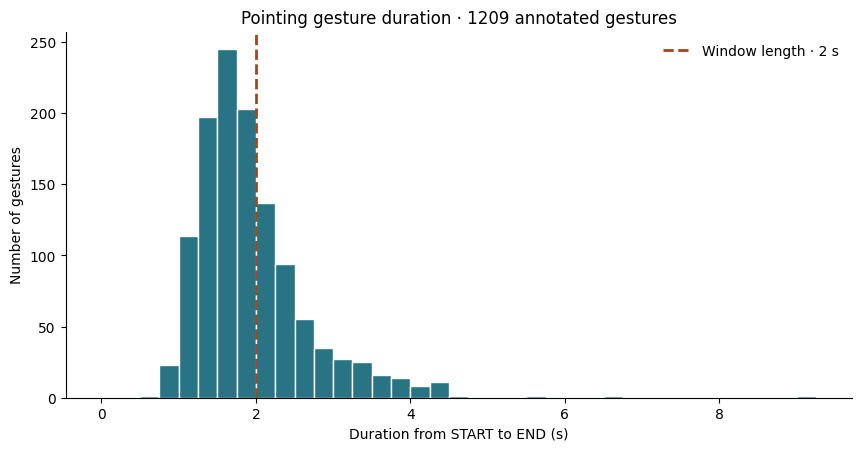

In [8]:
durations = pd.DataFrame(gesture_rows)["duration_s"]
long_gestures = int(durations.gt(WINDOW_S).sum())

duration_stats = pd.DataFrame([{
    "gestures": len(durations),
    "mean_s": durations.mean(),
    "median_s": durations.median(),
    "sample_variance_s2": durations.var(ddof=1),
    "sample_sd_s": durations.std(ddof=1),
    "q1_s": durations.quantile(0.25),
    "q3_s": durations.quantile(0.75),
    "min_s": durations.min(),
    "max_s": durations.max(),
    "window_s": WINDOW_S,
    "longer_than_window": long_gestures,
    "longer_than_window_pct": 100 * long_gestures / len(durations),
}])
duration_stats.to_csv(run_dir / "gesture_duration_statistics.csv", index=False)
display(duration_stats.T.rename(columns={0: "Value"}).round(3))

bin_width_s = 0.25
last_edge = np.ceil(durations.max() / bin_width_s) * bin_width_s
bins = np.arange(0, last_edge + bin_width_s, bin_width_s)
fig, ax = plt.subplots(figsize=(8.5, 4.4), layout="constrained")
ax.hist(durations, bins=bins, color="#287485", edgecolor="white")
ax.axvline(WINDOW_S, color="#a34522", ls="--", lw=2, label=f"Window length · {WINDOW_S:g} s")
ax.set(
    title=f"Pointing gesture duration · {len(durations)} annotated gestures",
    xlabel="Duration from START to END (s)",
    ylabel="Number of gestures",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(run_dir / "gesture_duration_histogram.png", dpi=220)
plt.show()


6 · Participant statistics
- Count usable recordings and gestures for each participant.
- Calculate median gesture duration and median START-to-POINTING time.
- Sort participants by gesture count.
- Display the table and save participant_gesture_statistics.csv.

In [9]:
gestures_df = pd.DataFrame(gesture_rows)

participant_stats = (
    gestures_df.groupby(["participant_id", "split"], as_index=False)
    .agg(
        n_recordings=("recording_id", "nunique"),
        n_gestures=("duration_s", "size"),
        median_duration_s=("duration_s", "median"),
        median_start_to_pointing_s=("start_to_pointing_s", "median"),
    )
    .sort_values("n_gestures", ascending=False)
    .reset_index(drop=True)
)

display(participant_stats.round(2))
participant_stats.to_csv(
    run_dir / "participant_gesture_statistics.csv",
    index=False,
)

,participant_id,split,n_recordings,n_gestures,median_duration_s,median_start_to_pointing_s
0,Sara,validation,3,84,1.23,0.63
1,Shaghayegh,train,3,81,1.64,0.54
2,Aliakbar,validation,3,79,1.82,0.97
3,Andrea,validation,3,78,1.76,0.90
4,Romain,train,3,78,1.20,0.55
5,Martina,train,3,78,2.75,0.92
6,Giulia,train,3,78,2.29,0.88
7,Greta,train,3,78,3.61,1.53
8,Piero Paolo,train,3,78,1.43,0.62
9,Francesco,test,3,78,1.78,0.63


## 7 · Visual comparison across recordings

- Generate one plot for every successfully processed recording.
- Show the first annotated gesture and automatically select the wrist with the largest START-to-POINTING displacement.
- Use seconds relative to START and shared vertical scales across all recordings.
- Save individual PNG files and a multipage comparison PDF under wrist_plots.
- Display overview pages with up to six recordings each.

Each overview row shows camera and pelvis-centred coordinates for the same recording. Only recordings that passed the earlier checks appear. Wrist selection is automatic and should be checked against the video when tracking looks unusual.


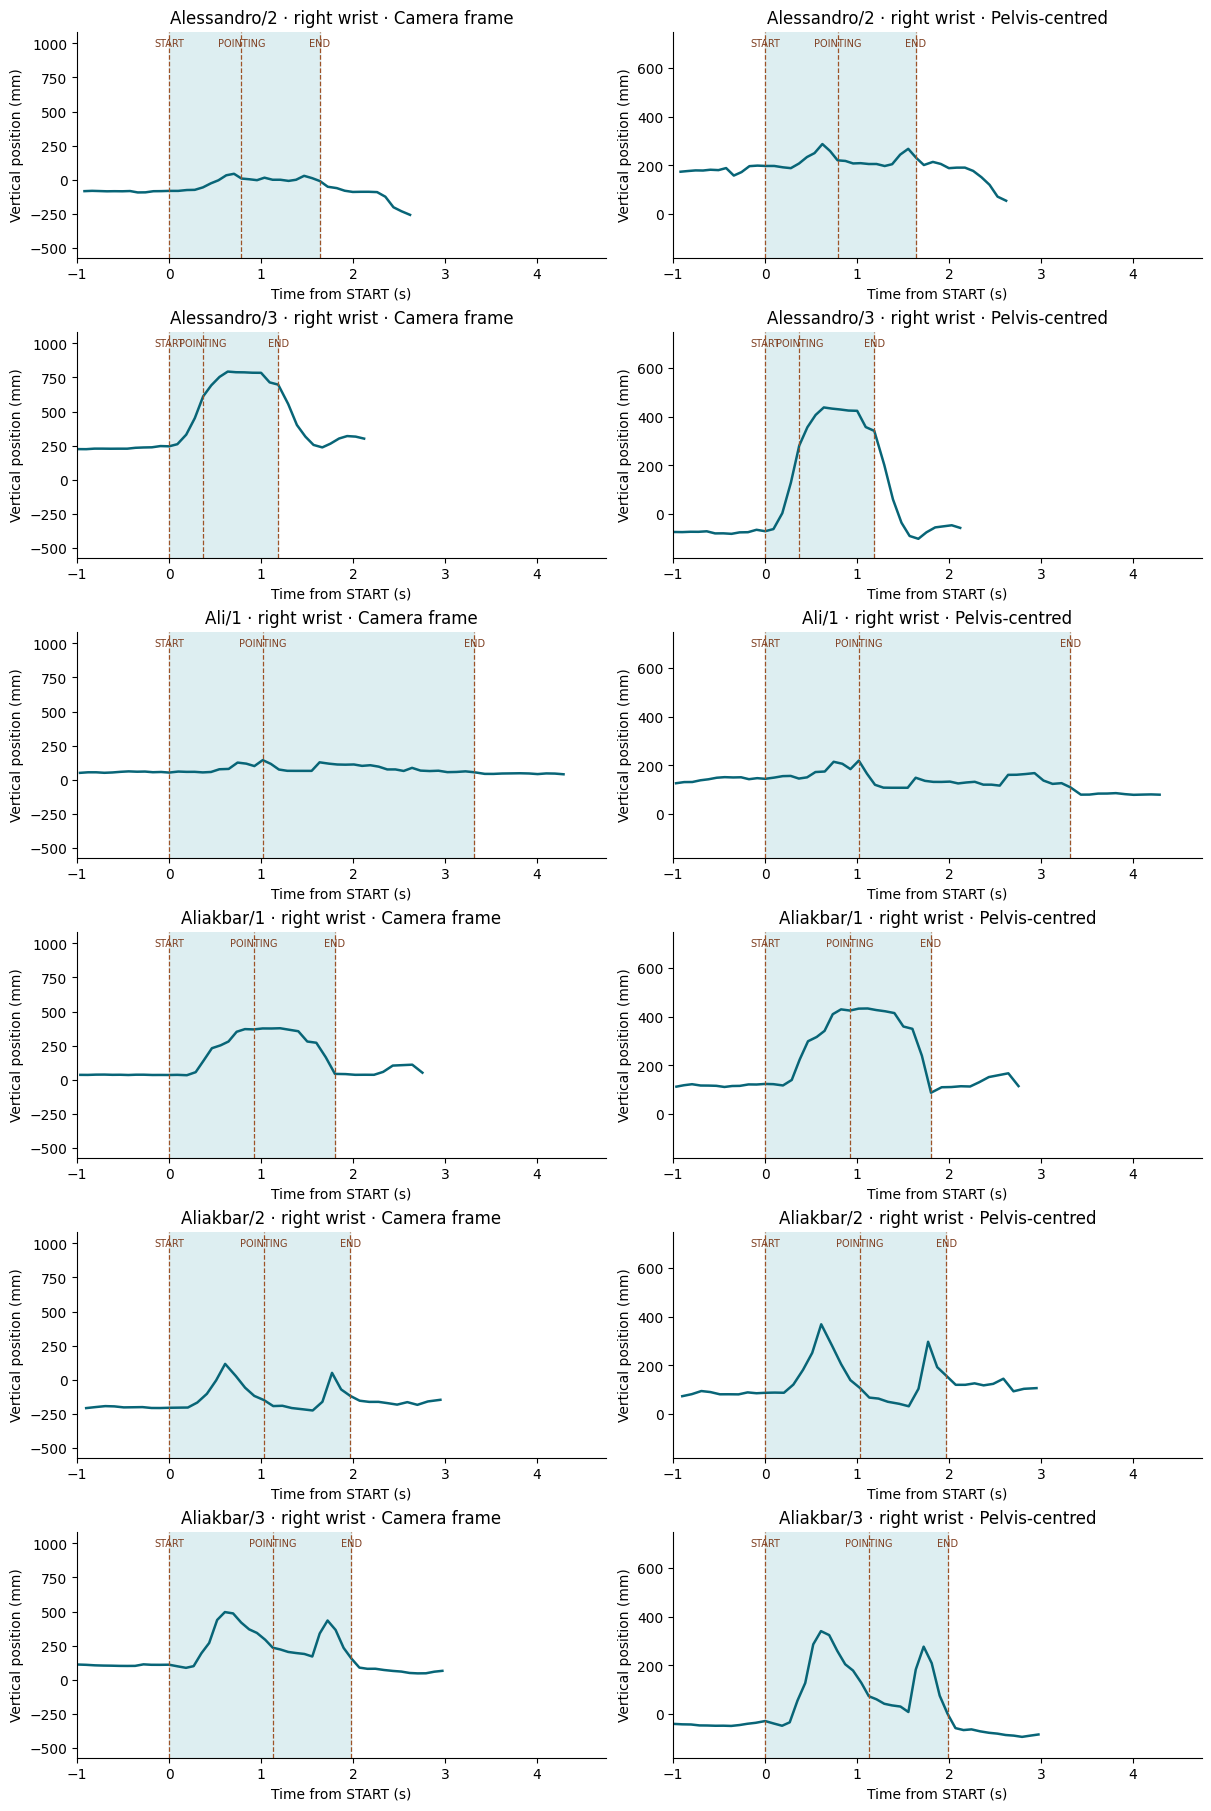

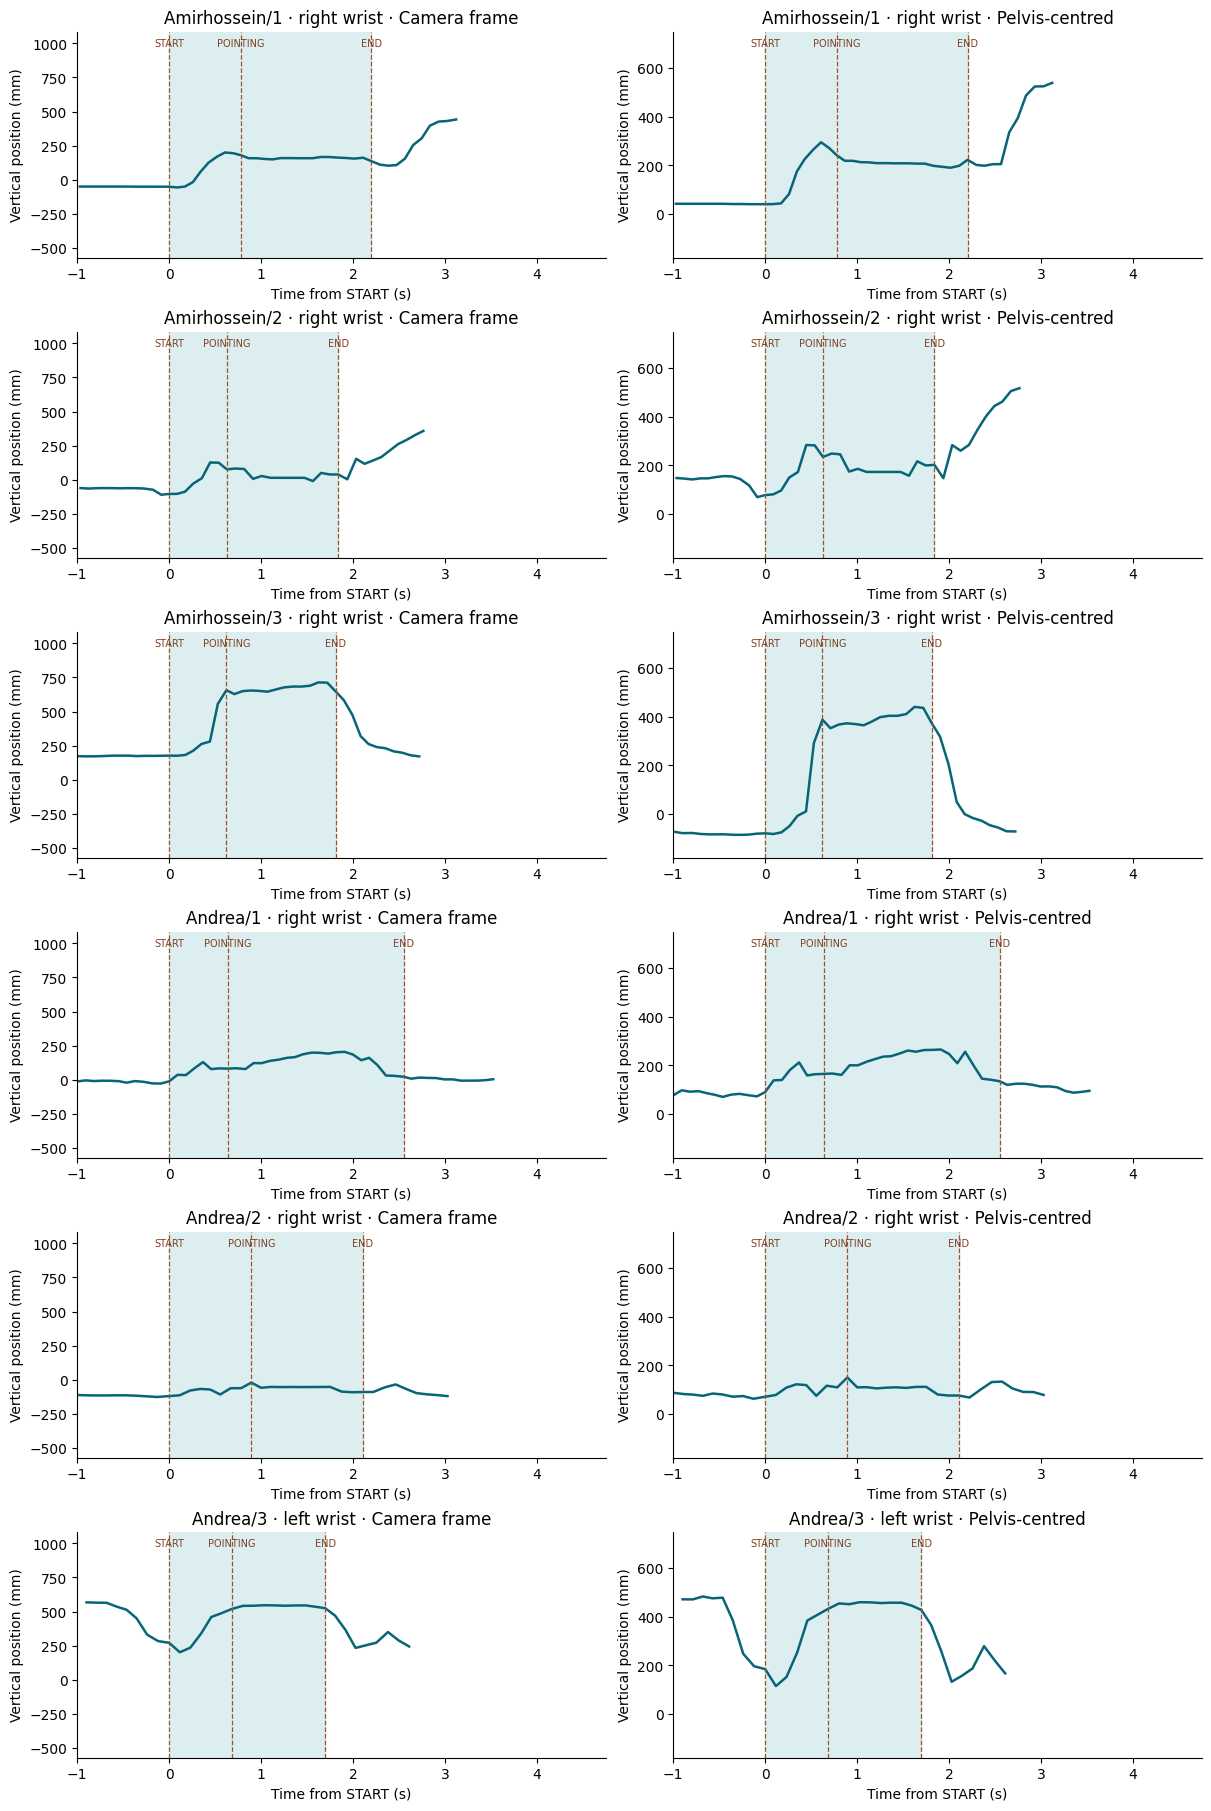

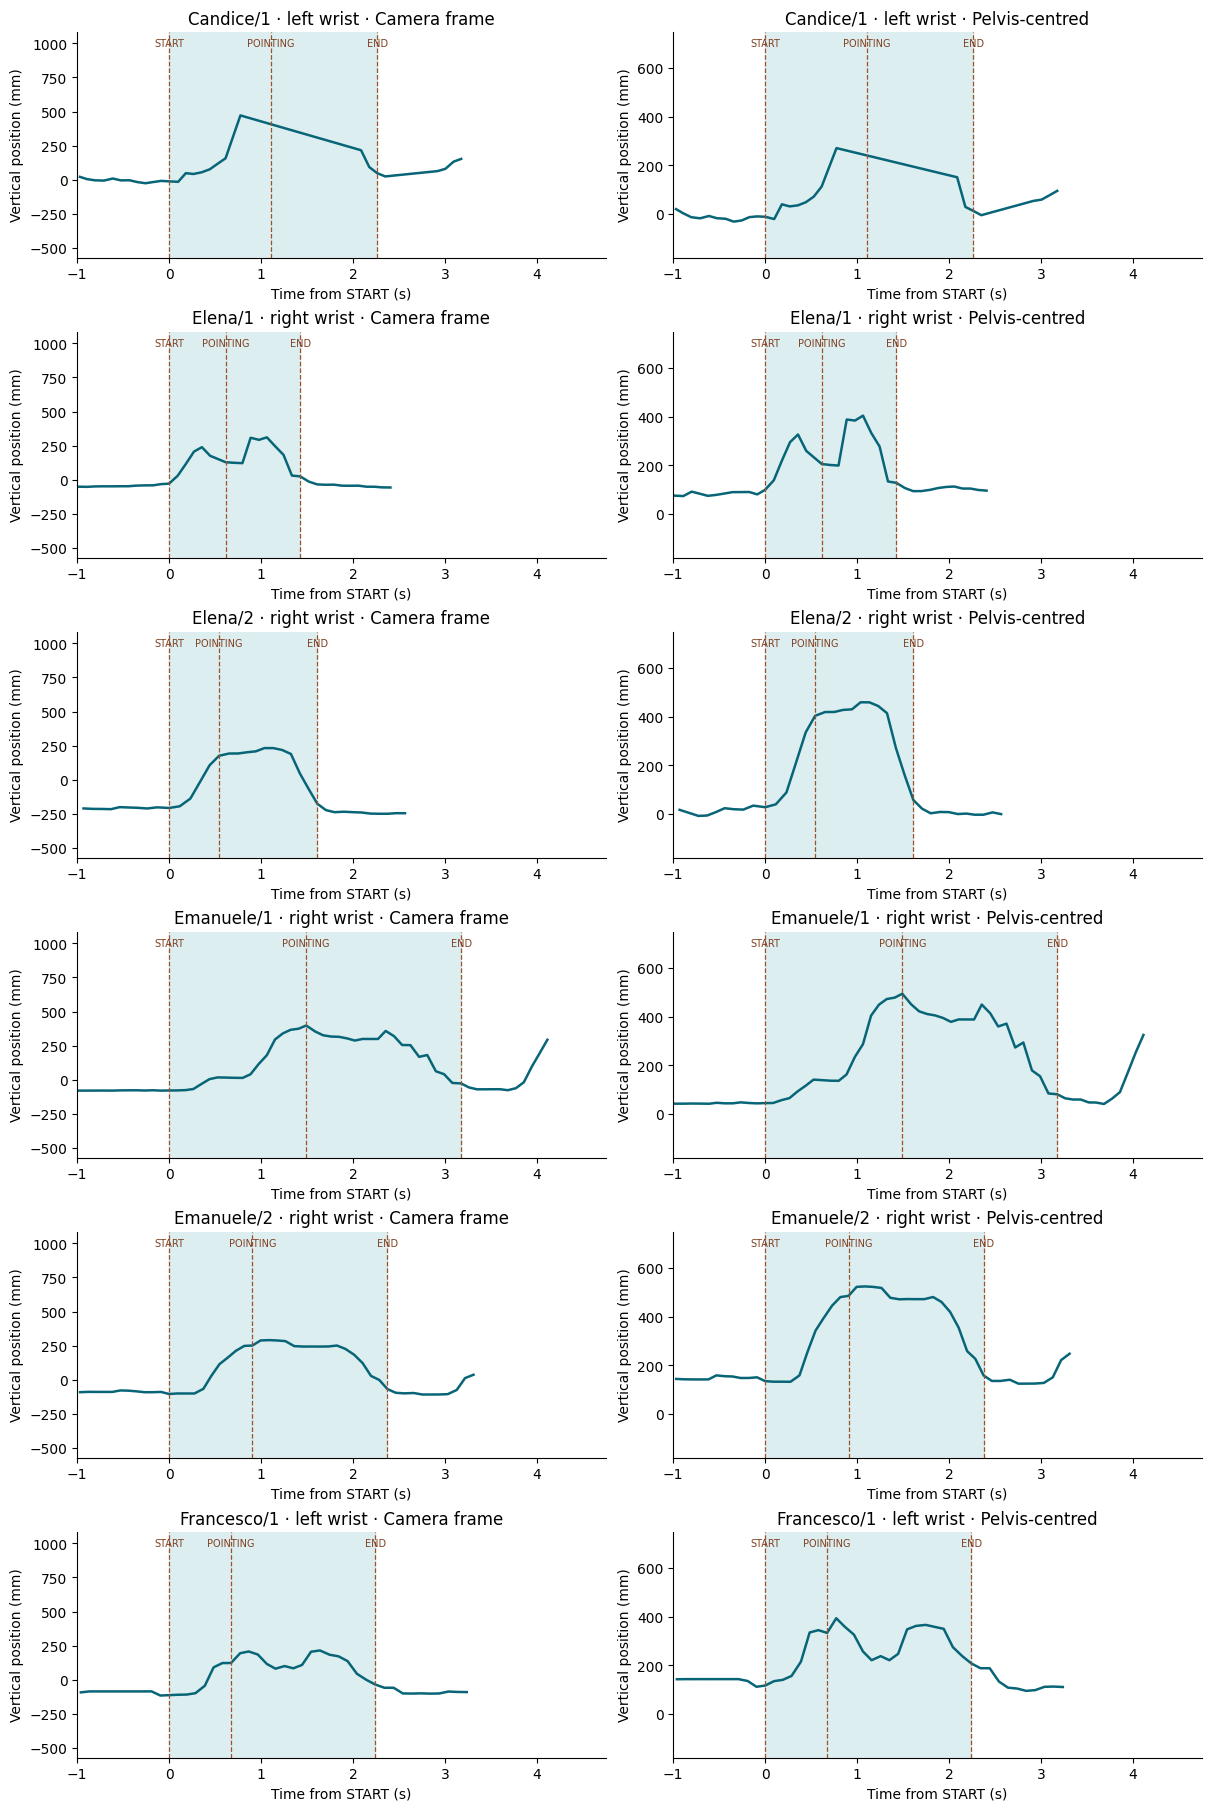

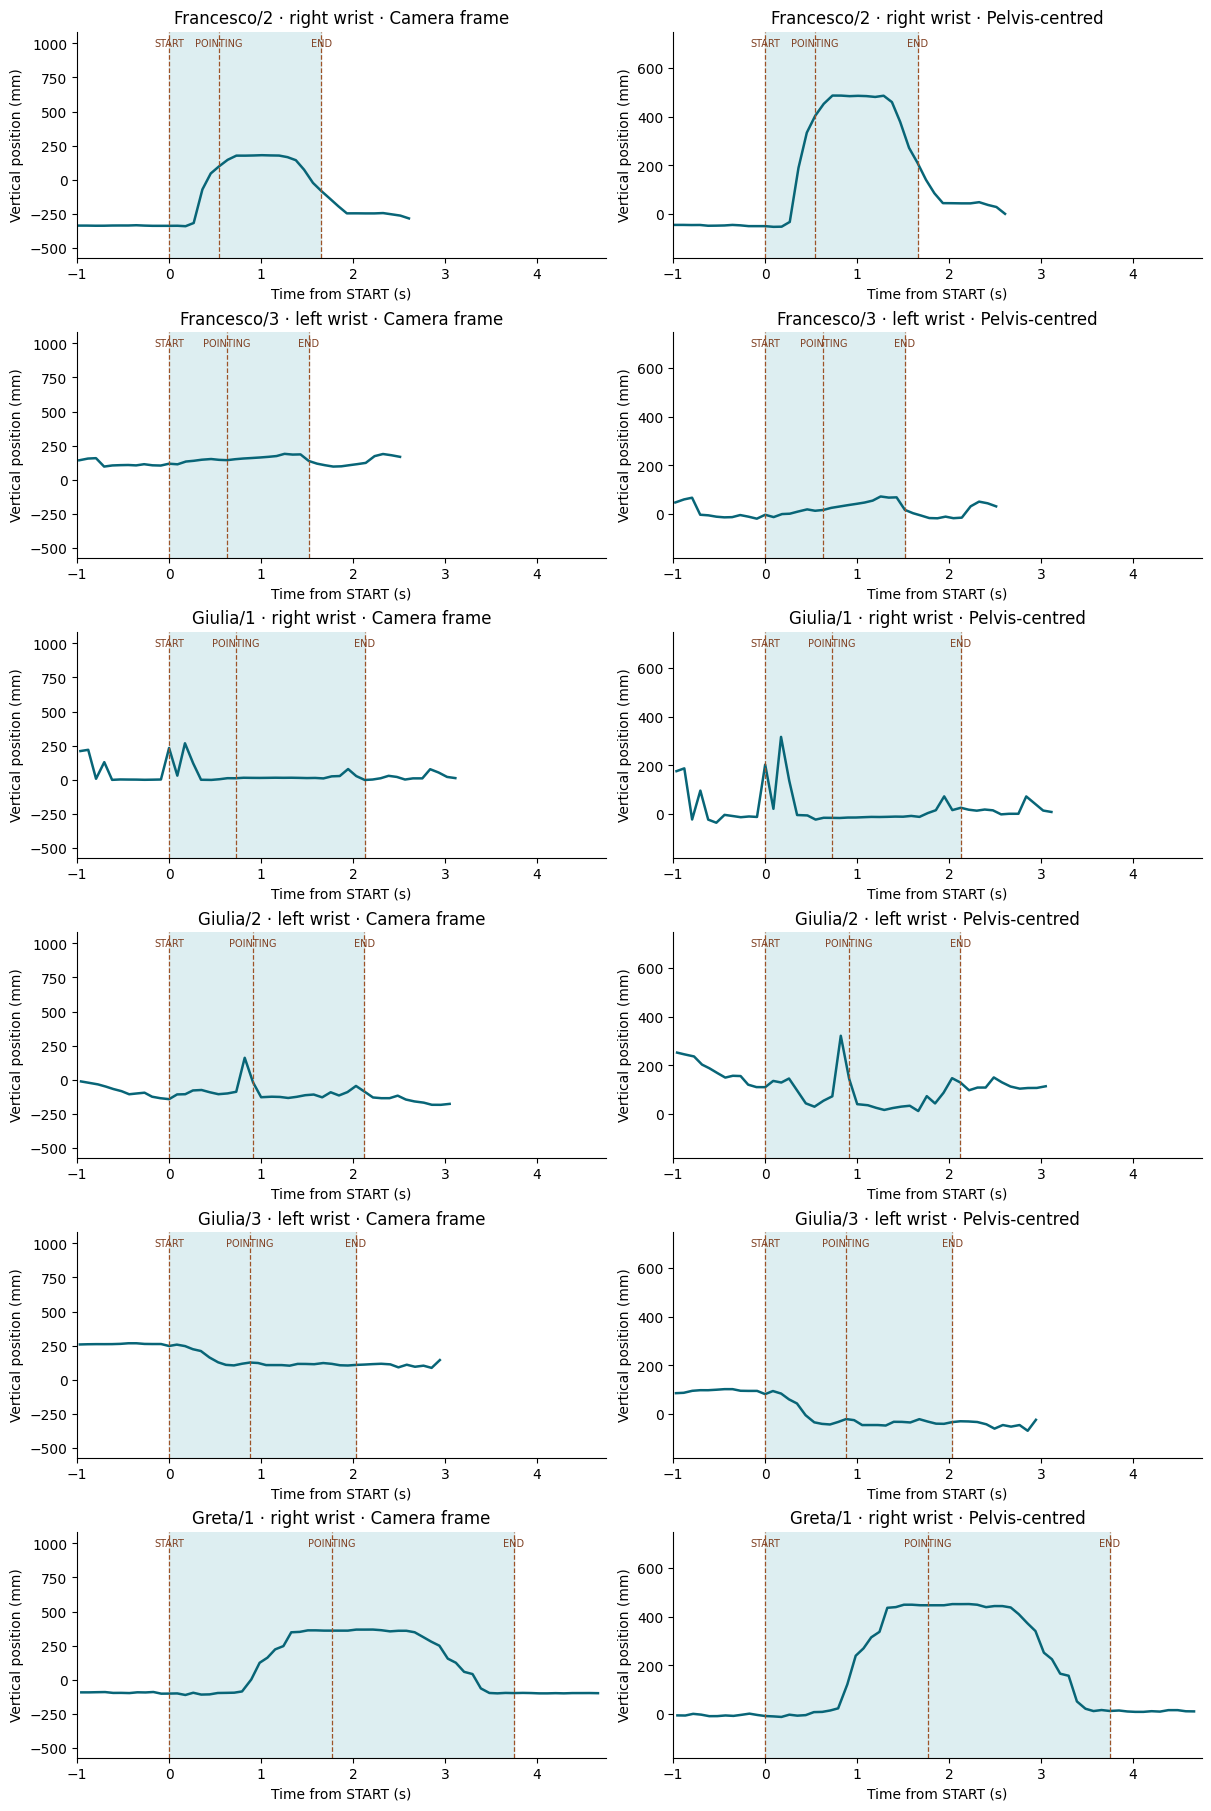

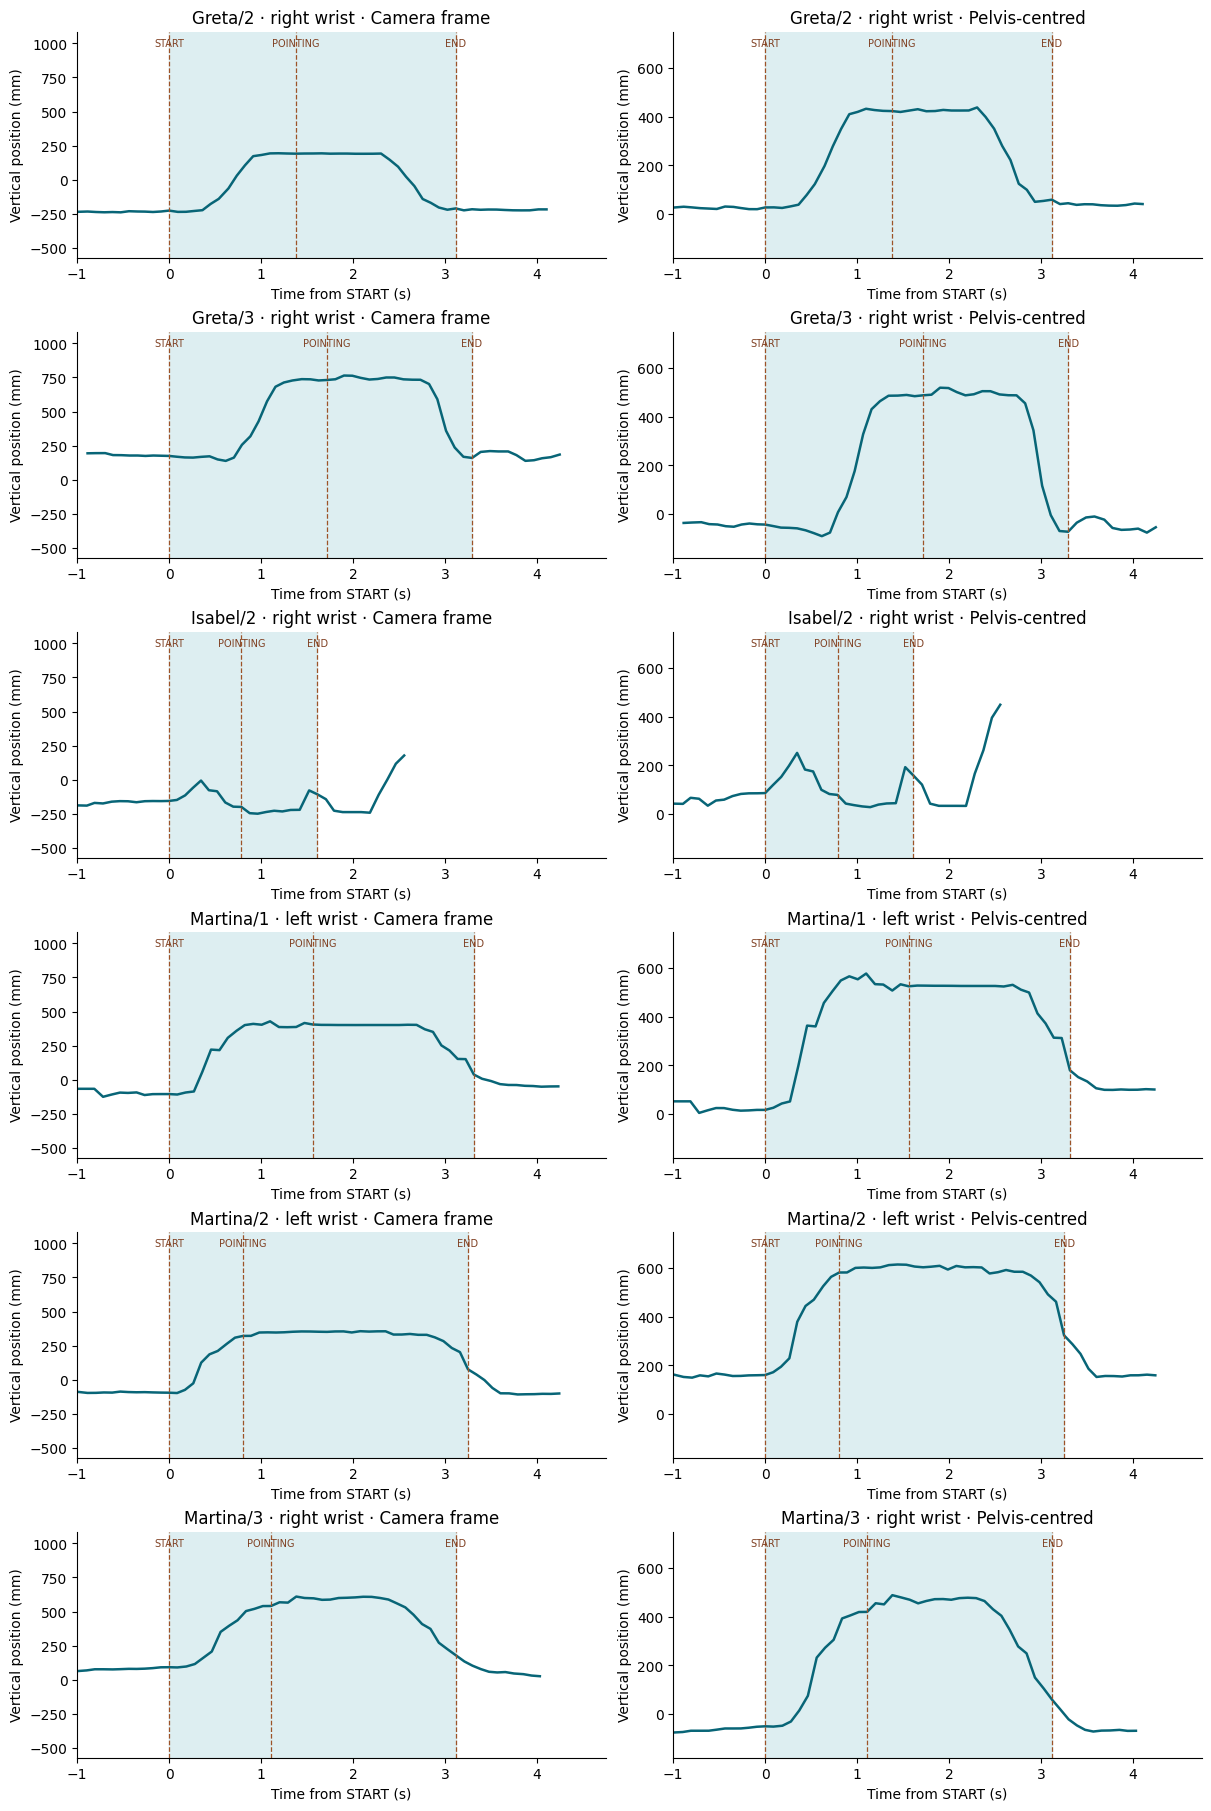

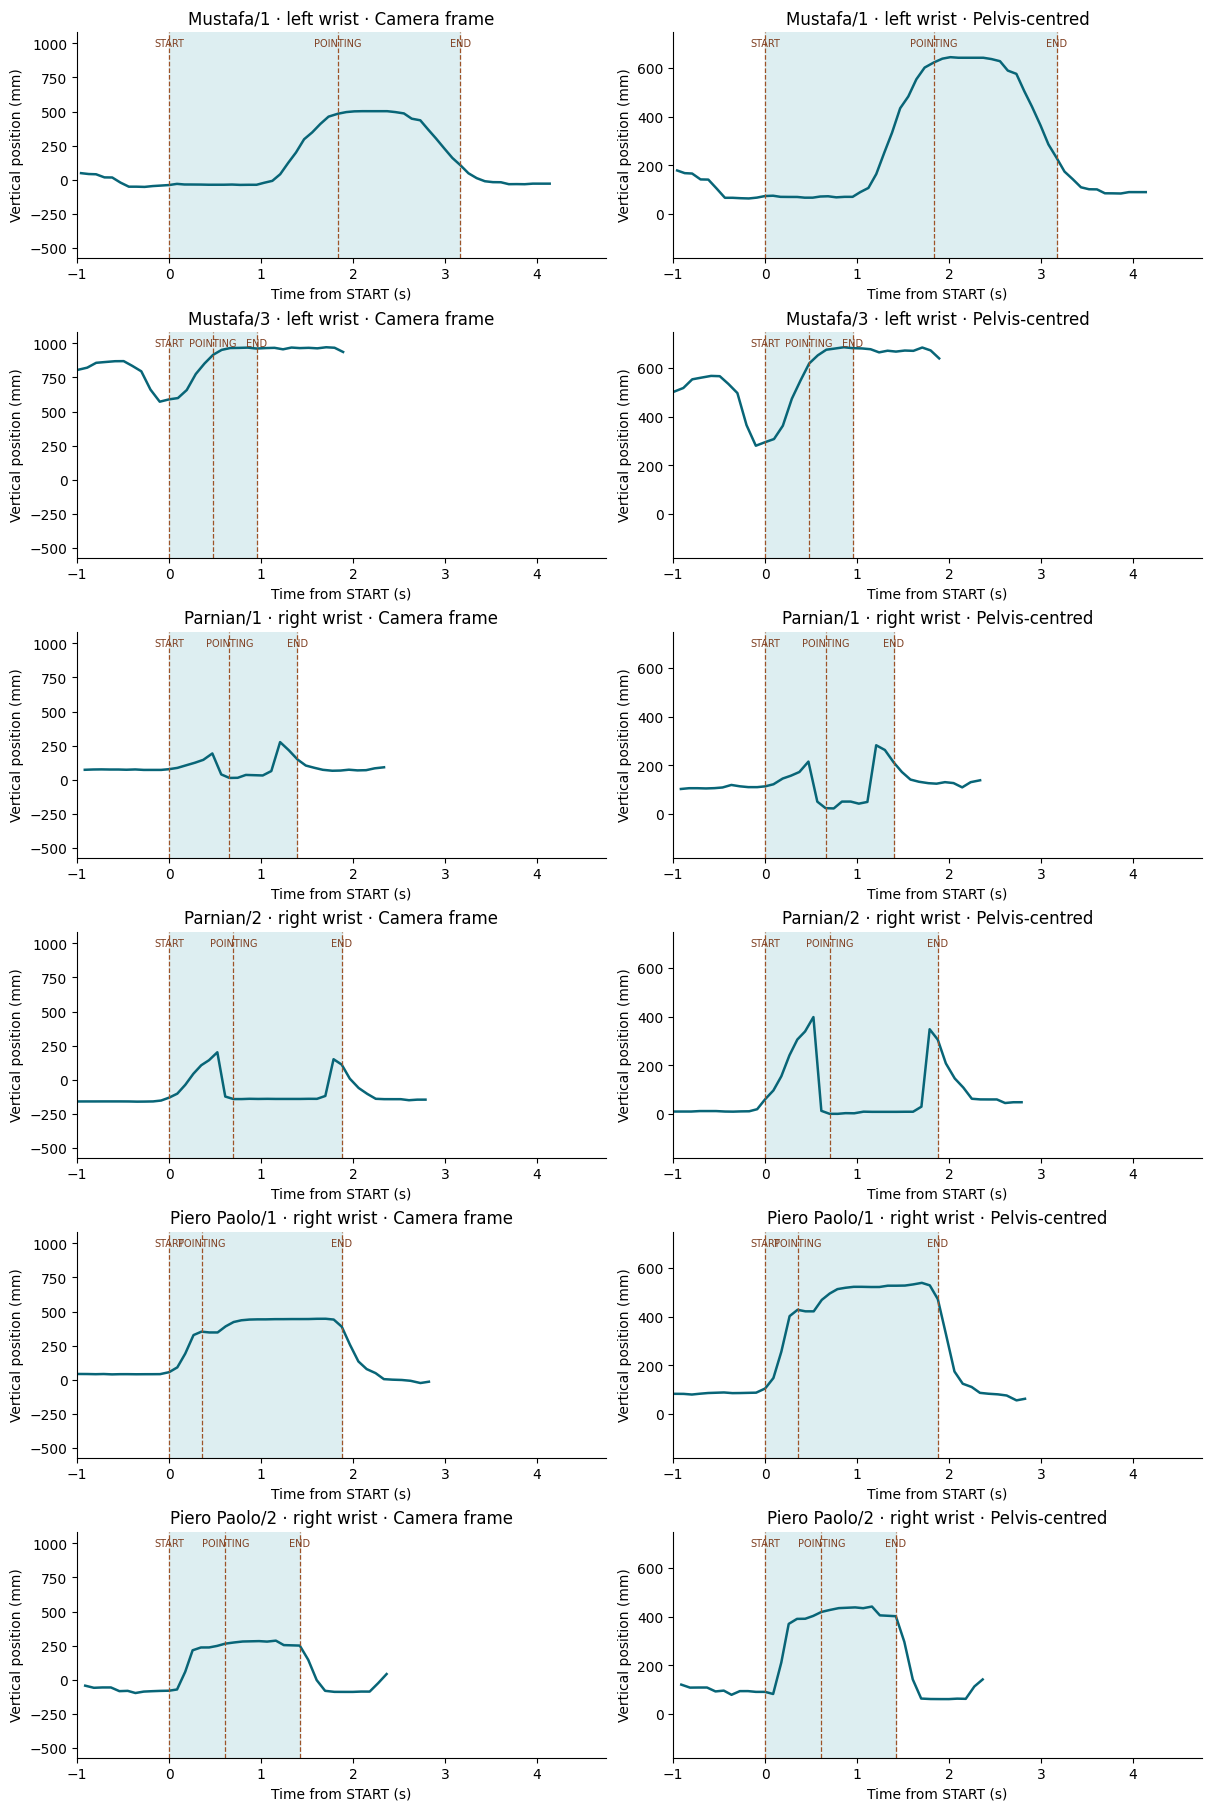

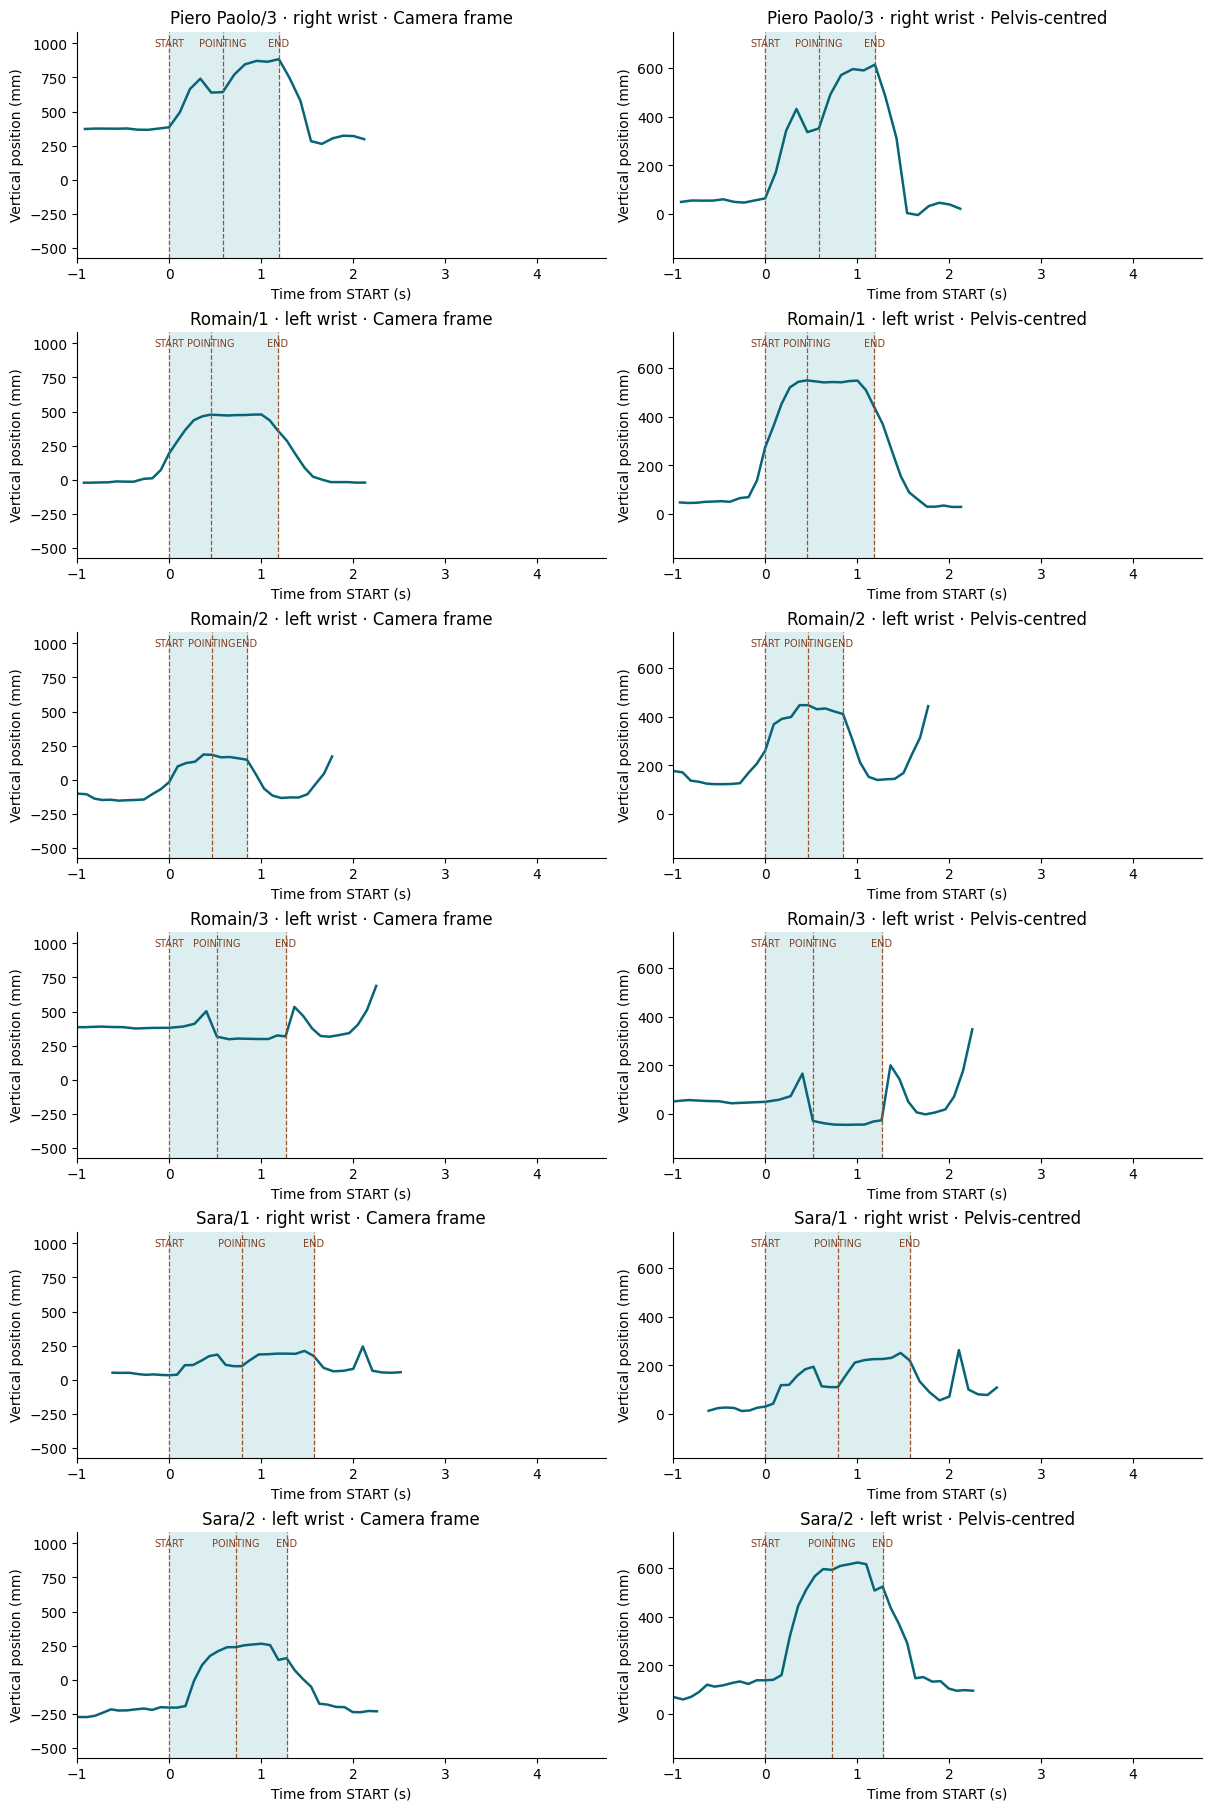

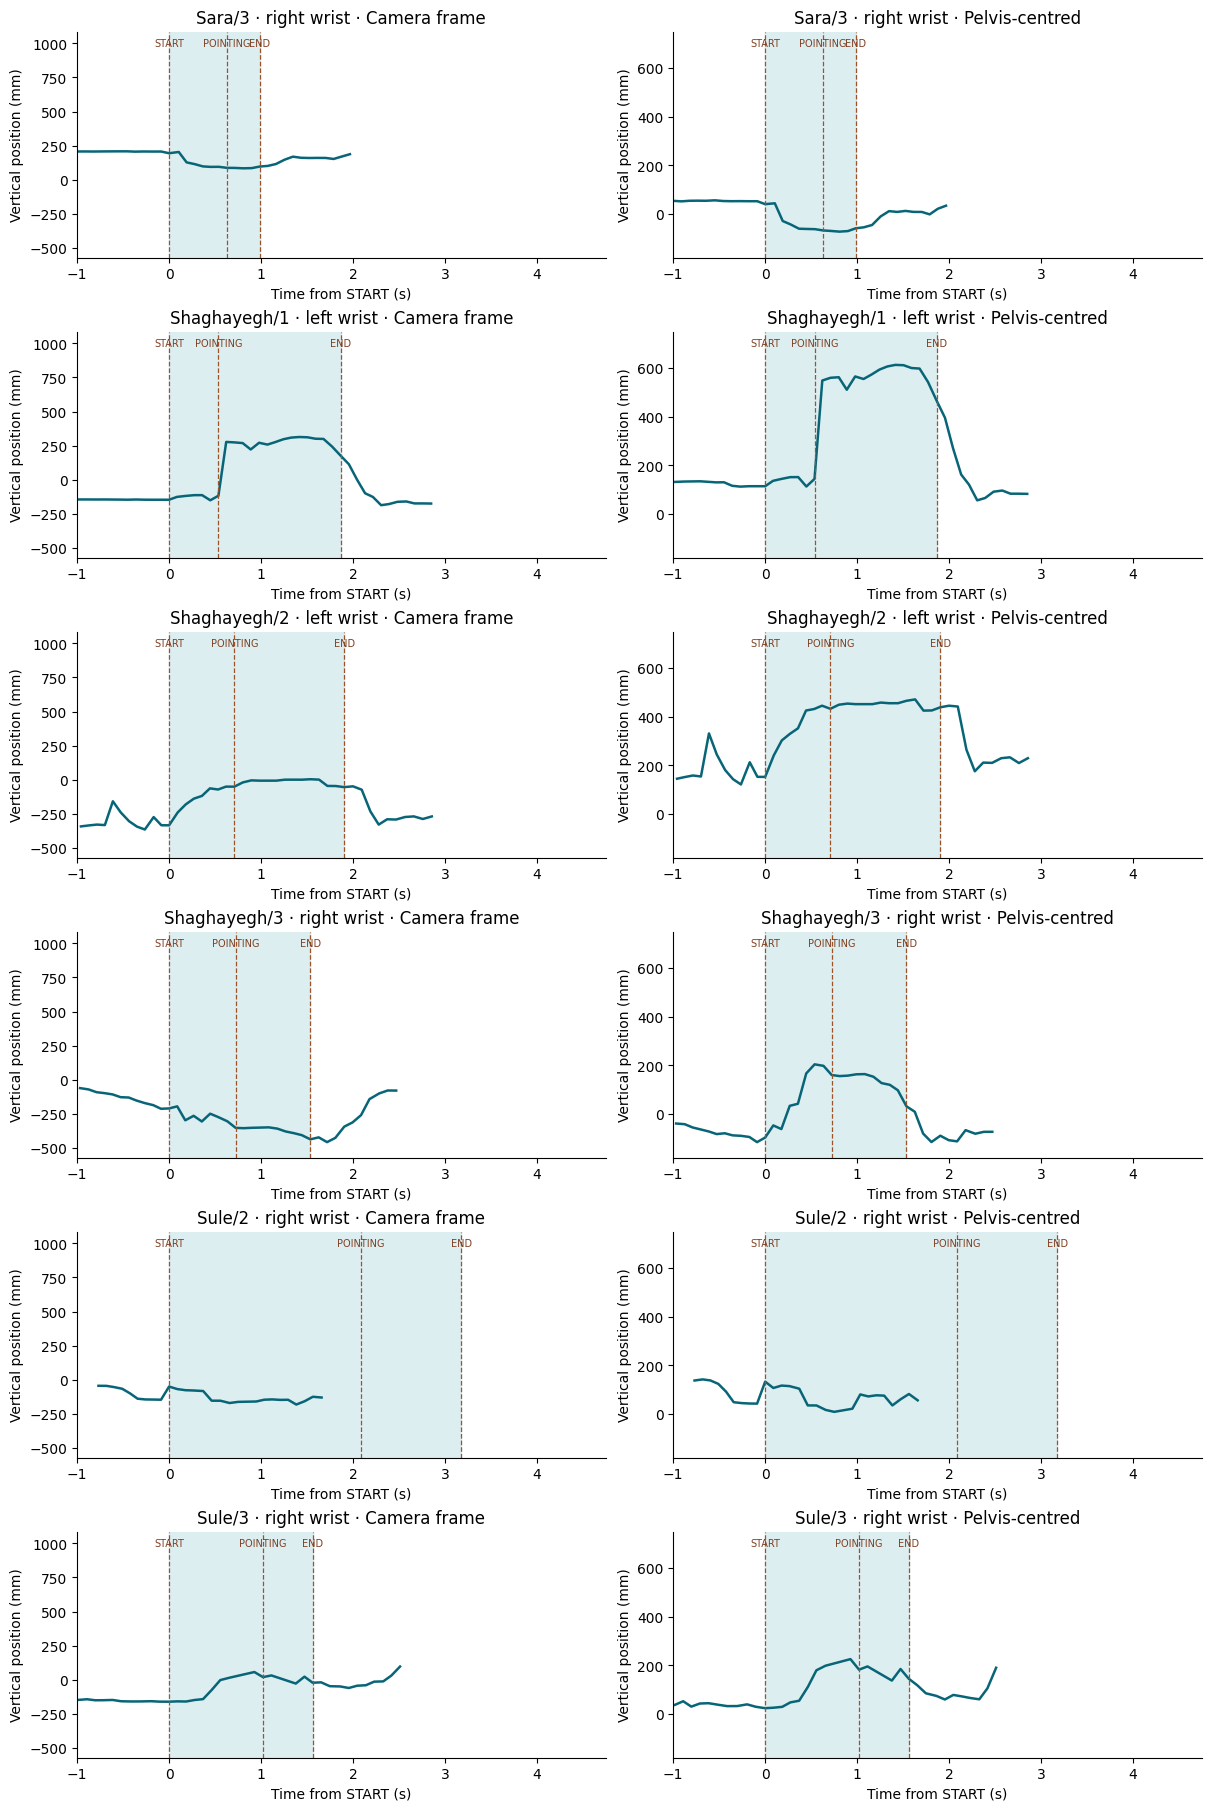

Generated 48 recording plots.
Files saved to /content/drive/MyDrive/pw2_processed/run_u80t1plc/wrist_plots


/content/drive/MyDrive/pw2_processed/run_u80t1plc/wrist_plots/all_recordings_comparison.pdf

In [10]:
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import FileLink

plot_dir = run_dir / "wrist_plots"
plot_dir.mkdir(exist_ok=True)
plot_examples = []

for metadata, recording, _ in recordings:
    start, pointing, end = recording["gestures"][0]
    time = recording["time"]
    indices = np.abs(time[:, None] - np.array([start, pointing])).argmin(axis=0)
    displacement = (
        recording["centered"][indices[1], WRISTS, :]
        - recording["centered"][indices[0], WRISTS, :]
    )
    wrist = WRISTS[int(np.linalg.norm(displacement, axis=1).argmax())]
    view = (time >= start - 1) & (time <= end + 1)
    plot_examples.append({
        "recording_id": metadata["recording_id"],
        "time": time[view] - start,
        "camera": -recording["xyz"][view, wrist, 1],
        "centered": -recording["centered"][view, wrist, 1],
        "pointing": pointing - start,
        "end": end - start,
        "side": "left" if wrist == WRISTS[0] else "right",
    })

# Use one vertical scale per coordinate system across the whole comparison.
plot_limits = {}
for coordinate in ("camera", "centered"):
    values = np.concatenate([example[coordinate] for example in plot_examples])
    low, high = values.min(), values.max()
    margin = max((high - low) * 0.08, 10)
    plot_limits[coordinate] = (low - margin, high + margin)
time_limits = (-1, max(example["end"] for example in plot_examples) + 1)


def draw_wrist_pair(axes, example):
    for ax, coordinate, title in zip(
        axes, ("camera", "centered"), ("Camera frame", "Pelvis-centred")
    ):
        ax.axvspan(0, example["end"], color="#ddeef1")
        ax.plot(example["time"], example[coordinate], color="#086577", lw=1.8)
        for instant, label in zip(
            (0, example["pointing"], example["end"]), EVENT_ORDER
        ):
            ax.axvline(instant, ls="--", color="#9d5328", lw=0.9)
            ax.text(
                instant, 0.97, label.upper(),
                transform=ax.get_xaxis_transform(), ha="center", va="top",
                fontsize=7, color="#7f3f21",
            )
        ax.set(
            title=f'{example["recording_id"]} · {example["side"]} wrist · {title}',
            xlabel="Time from START (s)", ylabel="Vertical position (mm)",
            xlim=time_limits, ylim=plot_limits[coordinate],
        )
        ax.spines[["right", "top"]].set_visible(False)


for index, example in enumerate(plot_examples, 1):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
    draw_wrist_pair(axes, example)
    fig.savefig(plot_dir / f"recording_{index:04d}.png", dpi=170)
    plt.close(fig)

# A manifest links each filename to its participant and recording.
pd.DataFrame([
    {
        "recording_id": example["recording_id"],
        "selected_wrist": example["side"],
        "plot_file": f"recording_{index:04d}.png",
    }
    for index, example in enumerate(plot_examples, 1)
]).to_csv(plot_dir / "plot_index.csv", index=False)

pdf_path = plot_dir / "all_recordings_comparison.pdf"
with PdfPages(pdf_path) as pdf:
    for offset in range(0, len(plot_examples), 6):
        page = plot_examples[offset:offset + 6]
        fig, axes = plt.subplots(
            len(page), 2, figsize=(12, 3 * len(page)),
            squeeze=False, layout="constrained",
        )
        for row_axes, example in zip(axes, page):
            draw_wrist_pair(row_axes, example)
        pdf.savefig(fig)
        display(fig)
        plt.close(fig)

print(f"Generated {len(plot_examples)} recording plots.")
print(f"Files saved to {plot_dir}")
display(FileLink(str(pdf_path)))
